In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import json
import re
from pathlib import Path
from collections import defaultdict
import yaml

In [2]:
# ── Configuration (edit these) ──────────────────────────────────────
TRAINING_DIR = "../runs/training"
MODEL_NAME   = "dirgnn_no_zero_edges_tuned"   # matches output.name in config.yaml
SPLIT        = "test"                         # which split to read from metrics.json
METRIC       = "rmse"                         # the single metric to extract
# ─────────────────────────────────────────────────────────────────────

# Find matching folders: {model_name}_{YYYYMMDD}_{HHMMSS}
pattern = re.compile(rf"^{re.escape(MODEL_NAME)}(_\d{{8}}_\d{{6}})?$")
folders = [
    d for d in sorted(Path(TRAINING_DIR).iterdir())
    if d.is_dir() and pattern.match(d.name)
]

if not folders:
    raise FileNotFoundError(
        f"No folders matching '{MODEL_NAME}' found in '{TRAINING_DIR}'"
    )

print(f"Found {len(folders)} run folder(s)")

# Collect (dir_alpha, seed, metric_value)
grouped: dict[float, list[float]] = defaultdict(list)

for folder in folders:
    with open(folder / "config.yaml") as f:
        config = yaml.safe_load(f)
    with open(folder / "metrics.json") as f:
        metrics = json.load(f)

    alpha = config["model"]["dir_alpha"]   # e.g. 1.0  [1]
    seed  = config["seed"]                 # e.g. 0    [1]
    value = metrics[SPLIT][METRIC]         # e.g. metrics["test"]["rmse"]  [2]

    grouped[alpha].append(value)
    print(f"  {folder.name}  dir_alpha={alpha}  seed={seed}  {SPLIT}_{METRIC}={value:.4f}")

# Sort by alpha, average across seeds
alphas_no_zeros = sorted(grouped.keys())
values_no_zeros = [sum(grouped[a]) / len(grouped[a]) for a in alphas_no_zeros]

# ── Result ──────────────────────────────────────────────────────────
# alphas  = [0.5, 1.0, 2.0, ...]
# values  = [158.2, 159.53, ...]   (mean of test_rmse per alpha)
print(f"\nalphas: {alphas_no_zeros}")
print(f"{SPLIT}_{METRIC}: {values_no_zeros}")

Found 105 run folder(s)
  dirgnn_no_zero_edges_tuned_20261017_090106  dir_alpha=0.0  seed=0  test_rmse=162.4437
  dirgnn_no_zero_edges_tuned_20261017_090112  dir_alpha=0.0  seed=1  test_rmse=162.1601
  dirgnn_no_zero_edges_tuned_20261017_090118  dir_alpha=0.0  seed=2  test_rmse=162.6165
  dirgnn_no_zero_edges_tuned_20261017_090124  dir_alpha=0.0  seed=3  test_rmse=158.3313
  dirgnn_no_zero_edges_tuned_20261017_090129  dir_alpha=0.0  seed=4  test_rmse=156.7225
  dirgnn_no_zero_edges_tuned_20261017_090135  dir_alpha=0.1  seed=0  test_rmse=147.4993
  dirgnn_no_zero_edges_tuned_20261017_090141  dir_alpha=0.1  seed=1  test_rmse=154.0355
  dirgnn_no_zero_edges_tuned_20261017_090147  dir_alpha=0.1  seed=2  test_rmse=149.7859
  dirgnn_no_zero_edges_tuned_20261017_090153  dir_alpha=0.1  seed=3  test_rmse=150.6831
  dirgnn_no_zero_edges_tuned_20261017_090159  dir_alpha=0.1  seed=4  test_rmse=148.7961
  dirgnn_no_zero_edges_tuned_20261017_090205  dir_alpha=0.2  seed=0  test_rmse=148.0918
  dirgnn

In [3]:
# ── Configuration (edit these) ──────────────────────────────────────
TRAINING_DIR = "../runs/training"
MODEL_NAME   = "dirgnn_tuned"   
SPLIT        = "test"                       
METRIC       = "rmse"  
# ─────────────────────────────────────────────────────────────────────

# Find matching folders: {model_name}_{YYYYMMDD}_{HHMMSS}
pattern = re.compile(rf"^{re.escape(MODEL_NAME)}(_\d{{8}}_\d{{6}})?$")
folders = [
    d for d in sorted(Path(TRAINING_DIR).iterdir())
    if d.is_dir() and pattern.match(d.name)
]

if not folders:
    raise FileNotFoundError(
        f"No folders matching '{MODEL_NAME}' found in '{TRAINING_DIR}'"
    )

print(f"Found {len(folders)} run folder(s)")

# Collect (dir_alpha, seed, metric_value)
grouped: dict[float, list[float]] = defaultdict(list)

for folder in folders:
    with open(folder / "config.yaml") as f:
        config = yaml.safe_load(f)
    with open(folder / "metrics.json") as f:
        metrics = json.load(f)

    alpha = config["model"]["dir_alpha"]   # e.g. 1.0  [1]
    seed  = config["seed"]                 # e.g. 0    [1]
    value = metrics[SPLIT][METRIC]         # e.g. metrics["test"]["rmse"]  [2]

    grouped[alpha].append(value)
    print(f"  {folder.name}  dir_alpha={alpha}  seed={seed}  {SPLIT}_{METRIC}={value:.4f}")

# Sort by alpha, average across seeds
alphas = sorted(grouped.keys())
values = [sum(grouped[a]) / len(grouped[a]) for a in alphas]

# ── Result ──────────────────────────────────────────────────────────
# alphas  = [0.5, 1.0, 2.0, ...]
# values  = [158.2, 159.53, ...]   (mean of test_rmse per alpha)
print(f"\nalphas: {alphas}")
print(f"{SPLIT}_{METRIC}: {values}")

Found 105 run folder(s)
  dirgnn_tuned_20261017_091313  dir_alpha=0.0  seed=0  test_rmse=140.1345
  dirgnn_tuned_20261017_091320  dir_alpha=0.0  seed=1  test_rmse=134.9010
  dirgnn_tuned_20261017_091327  dir_alpha=0.0  seed=2  test_rmse=140.6233
  dirgnn_tuned_20261017_091334  dir_alpha=0.0  seed=3  test_rmse=135.6717
  dirgnn_tuned_20261017_091341  dir_alpha=0.0  seed=4  test_rmse=141.9754
  dirgnn_tuned_20261017_091347  dir_alpha=0.1  seed=0  test_rmse=143.6845
  dirgnn_tuned_20261017_091354  dir_alpha=0.1  seed=1  test_rmse=138.9990
  dirgnn_tuned_20261017_091401  dir_alpha=0.1  seed=2  test_rmse=140.4897
  dirgnn_tuned_20261017_091408  dir_alpha=0.1  seed=3  test_rmse=139.6173
  dirgnn_tuned_20261017_091415  dir_alpha=0.1  seed=4  test_rmse=139.3046
  dirgnn_tuned_20261017_091422  dir_alpha=0.2  seed=0  test_rmse=142.3344
  dirgnn_tuned_20261017_091429  dir_alpha=0.2  seed=1  test_rmse=138.0080
  dirgnn_tuned_20261017_091435  dir_alpha=0.2  seed=2  test_rmse=137.7322
  dirgnn_tuned

In [4]:
# load the two results
results_with_zeros = pd.DataFrame({"alpha": alphas, "val_rmse": values})
results_without_zeros = pd.DataFrame({"alpha": alphas_no_zeros, "val_rmse": values_no_zeros})

In [5]:
# process to define type
results_with_zeros['type'] = 'With 0-edges'
results_without_zeros['type'] = 'Without 0-edges'

# merge df
full_df = pd.concat([results_without_zeros, results_with_zeros])

<Axes: xlabel='alpha', ylabel='val_rmse'>

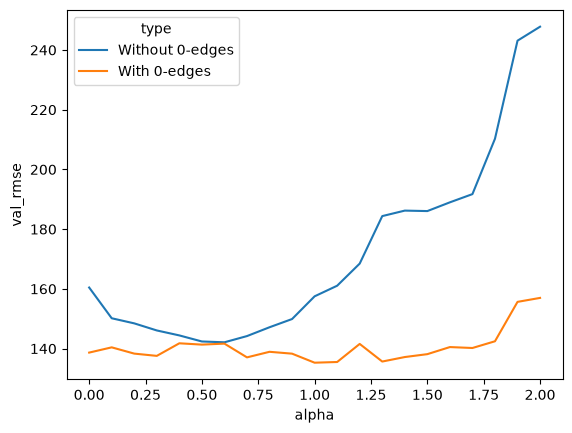

In [6]:
sns.lineplot(full_df, x='alpha', y='val_rmse', hue='type')

<Axes: xlabel='alpha', ylabel='val_rmse'>

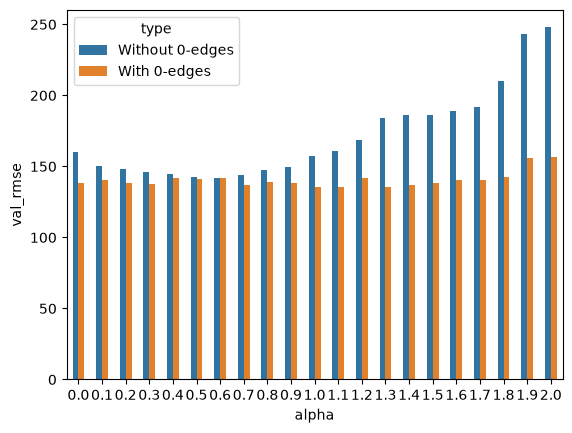

In [7]:
sns.barplot(full_df, x='alpha', y='val_rmse', hue='type', width=0.5)